# Part 2.2 — Logistic Regression
**Dataset:** 6-class Emotion Classification.

**Goal:** Implement binary **bigram** features and **multiclass softmax logistic regression from scratch using NumPy**, train with shuffled mini-batches/SGD, and compare against scikit-learn `LogisticRegression` and `SGDClassifier`.

**Shared split:** 80% train / 10% validation / 10% test, `SEED=42`, stratified. Build your bigram vocabulary using **training data only**. Do not touch test labels while tuning models.

## 1. Setup

In [3]:
from pathlib import Path
import sys

# Support launching Jupyter from the repo root or notebooks/ directory.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 42

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import lil_array
from sklearn.linear_model import LogisticRegression, SGDClassifier
from utils.data_loader import load_emotion_splits
from utils.preprocessing import tokenize
from utils.evaluation import (
    sklearn_evaluation, confusion_matrix_numpy, metrics_from_confusion_matrix_numpy,
)

## 2. Load and preprocess the shared 80/10/10 dataset
Student 2 uses **exactly the same** `load_emotion_splits(seed=42)` function.

In [5]:
data = load_emotion_splits(seed=SEED)

print(f"Train example: {data.train.texts[0]} \nlabel: {data.class_names[data.train.labels[0]]}")

train_tokens = [tokenize(text) for text in data.train.texts]
val_tokens = [tokenize(text) for text in data.val.texts]
test_tokens = [tokenize(text) for text in data.test.texts]

print('Example:', train_tokens[0], '\n', 'label:', data.class_names[data.train.labels[0]])

Train example: i feel excelent but sometimes theres just nothing to do especially since im not really keen on video games anymore i watch a bit of anime and some movies but theres just got to be more in my life 
label: joy
Example: ['i', 'feel', 'excelent', 'but', 'sometimes', 'theres', 'just', 'nothing', 'to', 'do', 'especially', 'since', 'im', 'not', 'really', 'keen', 'on', 'video', 'games', 'anymore', 'i', 'watch', 'a', 'bit', 'of', 'anime', 'and', 'some', 'movies', 'but', 'theres', 'just', 'got', 'to', 'be', 'more', 'in', 'my', 'life'] 
 label: joy


## 3. Binary Bigram Features

We build a vocabulary of unique bigrams from the training data. Each bigram is a column. Each sentence is a sparse binary row: 1 means the bigram is present and 0 means it is absent. 
Repeated bigrams still have value 1.

### Is this a good way of representing features?
**Advantages:**
- Captures word order and expressions like "not happy".
- Simple to implement and understand.
- Saves memory by storing only existing features.

**Limitations:**
- Creates a large vocabulary.
- Cannot recognize unseen bigrams.
- Misses relationships between distant words.
- Ignores how frequently a bigram appears.

In [6]:
def build_bigram_vocabulary(tokenized_train: list[list[str]]) -> dict[tuple[str, str], int]:
    vocabulary = {}

    for tokens in tokenized_train:
        for i in range(len(tokens) - 1):
            bigram = (tokens[i], tokens[i + 1])

            if bigram not in vocabulary:
                vocabulary[bigram] = len(vocabulary)

    return vocabulary


def vectorize_bigrams(tokenized_texts, vocabulary):
    X = lil_array((len(tokenized_texts), len(vocabulary)), dtype=np.float64)

    for row, tokens in enumerate(tokenized_texts):
        for i in range(len(tokens) - 1):
            bigram = (tokens[i], tokens[i + 1])
            if bigram in vocabulary:
                X[row, vocabulary[bigram]] = 1

    return X.tocsr()


### Build features and check binary behavior

In [7]:
bigram_vocab = build_bigram_vocabulary(train_tokens)
X_train = vectorize_bigrams(train_tokens, bigram_vocab)
X_val = vectorize_bigrams(val_tokens, bigram_vocab)
X_test = vectorize_bigrams(test_tokens, bigram_vocab)
print('Bigram vocabulary size:', len(bigram_vocab))
print('Training matrix shape:', X_train.shape)
print('example_X:', X_train[0].toarray())

Bigram vocabulary size: 91162
Training matrix shape: (12800, 91162)
example_X: [1. 1. 1. ... 0. 0. 0.]


## 4. Logistic Regression from Scratch

We implement multiclass Logistic Regression using NumPy.

The model calculates a score for each emotion class using the sparse binary feature vector and a bias. Softmax converts these scores into probabilities, and cross-entropy measures the prediction error.

**Training process:**
1. Initialize weights and biases to zero.
2. Shuffle the training data at each epoch.
3. Divide the data into mini-batches.
4. Calculate predictions and errors.
5. Update weights and biases using gradient descent.
6. Repeat for the specified number of epochs.

We track training and validation loss after each epoch. We also calculate the validation macro-F1 score and keep the model from the best-performing epoch.

Only training data is used to update the model's parameters.

Scores use `X @ W + b`; weight gradients use `X.T @ errors`. Sparse multiplication avoids a dense feature matrix.

In [8]:
class LogisticRegressionScratch:
    def __init__(self, num_features, num_classes,
                 learning_rate=1.0, epochs=60, batch_size=64, seed=42):

        self.num_classes = num_classes
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

        self.W = np.zeros((num_features, num_classes))
        self.b = np.zeros(num_classes)
        self.history_ = []

    def predict_proba(self, X):
        # Z = XW + b; P[i,c] = exp(Z[i,c]) / sum_k exp(Z[i,k]).
        scores = X @ self.W + self.b
        # Subtracting the row maximum leaves softmax unchanged and avoids overflow.
        scores -= scores.max(axis=1, keepdims=True)
        probabilities = np.exp(scores)
        return probabilities / probabilities.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def _loss(self, X, y):
        # Cross-entropy: L = -(1/m) * sum_i log(P[i, y[i]]).
        # Substitute softmax: -log(exp(z_true) / sum_c exp(z_c))
        #                  = log(sum_c exp(z_c)) - z_true.
        scores = X @ self.W + self.b
        scores = scores - scores.max(axis=1, keepdims=True)
        log_normalizer = np.log(np.exp(scores).sum(axis=1))
        return (log_normalizer - scores[np.arange(len(y)), y]).mean()

    def _train_batch(self, X_batch, y_batch):
        errors = self.predict_proba(X_batch)
        # dL/dZ = (P - Y) / m. Subtract 1 at each true-class position.
        errors[np.arange(len(y_batch)), y_batch] -= 1
        errors /= len(y_batch)

        # dL/dW = X * dL/dZ.
        self.W -= self.learning_rate * (X_batch.T @ errors)
        # dL/db = dL/dZ.
        self.b -= self.learning_rate * errors.sum(axis=0)

    def fit(self, X, y, X_val=None, y_val=None):
        y = np.asarray(y, dtype=int)
        if (X_val is None) != (y_val is None):
            raise ValueError("Provide both validation features and labels")

        if y_val is not None:
            y_val = np.asarray(y_val, dtype=int)

        self.W.fill(0)
        self.b.fill(0)
        self.history_ = []

        rng = np.random.default_rng(self.seed)
        best_f1 = -1
        self.best_epoch_ = self.epochs

        for epoch in range(1, self.epochs + 1):
            # Shuffle training samples
            indices = rng.permutation(len(y))

            # Mini-batch gradient descent
            for start in range(0, len(y), self.batch_size):
                batch_indices = indices[start:start + self.batch_size]

                X_batch = X[batch_indices]
                y_batch = y[batch_indices]

                self._train_batch(X_batch, y_batch)

            # Record training loss
            record = {
                "epoch": epoch,
                "train_loss": self._loss(X, y)
            }

            # Evaluate on validation data
            if X_val is not None and y_val is not None:
                record["val_loss"] = self._loss(X_val, y_val)

                predictions = self.predict(X_val)
                cm = confusion_matrix_numpy(y_val, predictions, self.num_classes)
                f1 = metrics_from_confusion_matrix_numpy(cm)["macro_f1"]
                record["val_macro_f1"] = f1

                # Save the best model
                if f1 > best_f1:
                    best_f1 = f1
                    best_weights = self.W.copy()
                    best_bias = self.b.copy()
                    self.best_epoch_ = epoch

            self.history_.append(record)

        # Restore the best-performing model
        if X_val is not None and y_val is not None:
            self.W = best_weights
            self.b = best_bias

        return self

## 5. Train, validate, and plot loss

/run/media/braamostafa/Stuff/MyStuff/learning/engineering/year 4 (final)/semester 1/nlp/labs/lab 1/Natural-Language-Processing-Lab-1/utils/evaluation.py:91: RuntimeWarning: invalid value encountered in divide
  precision = np.where(denom_p > 0, tp / denom_p, 0.0)
/run/media/braamostafa/Stuff/MyStuff/learning/engineering/year 4 (final)/semester 1/nlp/labs/lab 1/Natural-Language-Processing-Lab-1/utils/evaluation.py:99: RuntimeWarning: invalid value encountered in divide
  f1 = np.where(denom_f1 > 0, 2 * precision * recall / denom_f1, 0.0)


Scratch: learning rate=0.5, best epoch=57, validation macro-F1=0.5103


/run/media/braamostafa/Stuff/MyStuff/learning/engineering/year 4 (final)/semester 1/nlp/labs/lab 1/Natural-Language-Processing-Lab-1/utils/evaluation.py:91: RuntimeWarning: invalid value encountered in divide
  precision = np.where(denom_p > 0, tp / denom_p, 0.0)
/run/media/braamostafa/Stuff/MyStuff/learning/engineering/year 4 (final)/semester 1/nlp/labs/lab 1/Natural-Language-Processing-Lab-1/utils/evaluation.py:99: RuntimeWarning: invalid value encountered in divide
  f1 = np.where(denom_f1 > 0, 2 * precision * recall / denom_f1, 0.0)


Scratch: learning rate=2.0, best epoch=47, validation macro-F1=0.5537


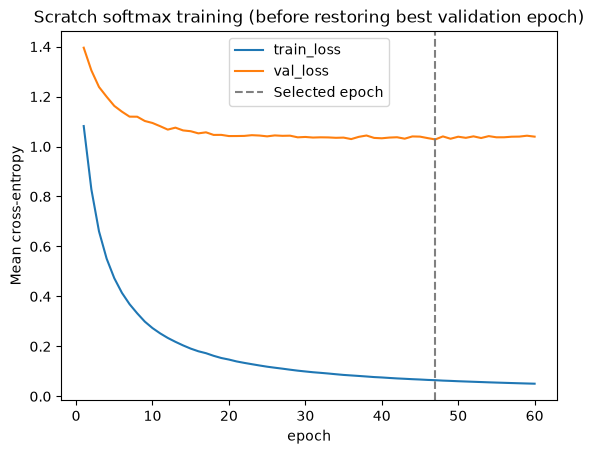

In [9]:
scratch_candidates = []
for rate in (0.5, 2.0):
    model = LogisticRegressionScratch(len(bigram_vocab), data.num_classes,
                                      learning_rate=rate, epochs=60, seed=SEED)
    model.fit(X_train, data.train.labels, X_val, data.val.labels)
    report = sklearn_evaluation(data.val.labels, model.predict(X_val), data.num_classes)
    scratch_candidates.append((report['macro_f1'], model))
    print(f"Scratch: learning rate={rate}, best epoch={model.best_epoch_}, validation macro-F1={report['macro_f1']:.4f}")
scratch = max(scratch_candidates, key=lambda item: item[0])[1]
history = pd.DataFrame(scratch.history_)
history.plot(x='epoch', y=['train_loss', 'val_loss'], ylabel='Mean cross-entropy',
             title='Scratch softmax training (before restoring best validation epoch)')
plt.axvline(scratch.best_epoch_, linestyle='--', color='gray', label='Selected epoch')
plt.legend()
plt.show()

## 6. Scikit-learn Comparison

We compare our Logistic Regression implementation with two scikit-learn models:
- `LogisticRegression`
- `SGDClassifier`

All three models use the same training and validation data. We try different hyperparameters and select the best ones based on validation macro-F1.

In [10]:
models = {"NumPy softmax": scratch}

# 1. Scikit-learn Logistic Regression
best_score = -1

for C in [1.0, 10.0]:
    model = LogisticRegression(
        C=C,
        max_iter=1000,
        random_state=SEED
    )

    model.fit(X_train, data.train.labels)

    predictions = model.predict(X_val)
    report = sklearn_evaluation(data.val.labels, predictions, data.num_classes)

    score = report["macro_f1"]
    print(f"LogisticRegression (C={C}): {score:.4f}")

    if score > best_score:
        best_score = score
        models["sklearn LogisticRegression"] = model


# 2. SGD Classifier
best_score = -1

for alpha in [1e-4, 1e-5]:
    model = SGDClassifier(
        loss="log_loss",
        alpha=alpha,
        max_iter=1000,
        tol=1e-4,
        random_state=SEED
    )

    model.fit(X_train, data.train.labels)

    predictions = model.predict(X_val)
    report = sklearn_evaluation(data.val.labels, predictions, data.num_classes)

    score = report["macro_f1"]
    print(f"SGDClassifier (alpha={alpha}): {score:.4f}")

    if score > best_score:
        best_score = score
        models["sklearn SGDClassifier"] = model


# 3. Compare all three models
results = []

for name, model in models.items():

    predictions = model.predict(X_val)
    report = sklearn_evaluation(data.val.labels, predictions, data.num_classes)

    results.append({
        "Model": name,
        "Precision": report["macro_precision"],
        "Recall": report["macro_recall"],
        "F1": report["macro_f1"]
    })

validation_results = pd.DataFrame(results)
display(validation_results)

LogisticRegression (C=1.0): 0.5055
LogisticRegression (C=10.0): 0.5414
SGDClassifier (alpha=0.0001): 0.5093
SGDClassifier (alpha=1e-05): 0.5410


,Model,Precision,Recall,F1
0,NumPy softmax,0.673708,0.512597,0.553700
1,sklearn LogisticRegression,0.663099,0.501751,0.541435
2,sklearn SGDClassifier,0.628343,0.506075,0.540984


## 7. Final test evaluation
Keep the models selected on validation. Report test results without using them to retune the models. Confusion matrix rows are true labels; columns are predictions.

In [11]:
test_results = []
for name, model in models.items():
    predictions = model.predict(X_test)
    report = sklearn_evaluation(data.test.labels, predictions, data.num_classes)
    test_results.append({"Model": name,
                         "Accuracy": np.mean(predictions == data.test.labels),
                         "Precision": report["macro_precision"],
                         "Recall": report["macro_recall"],
                         "F1": report["macro_f1"]})
    print(name)
    display(pd.DataFrame({k: report[k] for k in ("precision", "recall", "f1")},
                         index=data.class_names))
    display(pd.DataFrame(report["confusion_matrix"],
                         index=data.class_names, columns=data.class_names))
test_results = pd.DataFrame(test_results)
display(test_results)

NumPy softmax


,precision,recall,f1
sadness,0.640934,0.764454,0.697266
joy,0.646970,0.796642,0.714047
love,0.719298,0.315385,0.438503
anger,0.636364,0.486111,0.551181
fear,0.750000,0.556701,0.639053
surprise,0.764706,0.228070,0.351351


,sadness,joy,love,anger,fear,surprise
sadness,357,80,4,20,6,0
joy,75,427,8,18,8,0
love,28,51,41,7,3,0
anger,47,52,1,105,10,1
fear,38,33,1,11,108,3
surprise,12,17,2,4,9,13


sklearn LogisticRegression


,precision,recall,f1
sadness,0.644524,0.768737,0.701172
joy,0.646707,0.805970,0.717608
love,0.716981,0.292308,0.415301
anger,0.664596,0.495370,0.567639
fear,0.765957,0.556701,0.644776
surprise,0.750000,0.263158,0.389610


,sadness,joy,love,anger,fear,surprise
sadness,359,81,3,18,6,0
joy,74,432,9,15,6,0
love,29,52,38,6,5,0
anger,47,51,1,107,9,1
fear,35,36,0,11,108,4
surprise,13,16,2,4,7,15


sklearn SGDClassifier


,precision,recall,f1
sadness,0.619137,0.706638,0.660000
joy,0.631741,0.764925,0.691983
love,0.579710,0.307692,0.402010
anger,0.621469,0.509259,0.559796
fear,0.710526,0.556701,0.624277
surprise,0.750000,0.263158,0.389610


,sadness,joy,love,anger,fear,surprise
sadness,330,94,5,22,15,1
joy,79,410,19,19,9,0
love,28,49,40,8,5,0
anger,49,48,2,110,7,0
fear,35,32,1,14,108,4
surprise,12,16,2,4,8,15


,Model,Accuracy,Precision,Recall,F1
0,NumPy softmax,0.656875,0.693045,0.524560,0.565233
1,sklearn LogisticRegression,0.661875,0.698128,0.530374,0.572684
2,sklearn SGDClassifier,0.633125,0.652097,0.518062,0.554613


## Discussion

### Which approach performs better, and under what conditions?

In our experiment, **scikit-learn LogisticRegression performs best on the test set**, with macro-F1 **0.5727**, compared with **0.5652** for our NumPy model and **0.5546** for SGDClassifier. Our NumPy model performs best on validation (**0.5537**). All models use the same binary bigram features and split.

- **LogisticRegression:** A good choice for fixed datasets that fit in memory.
- **SGDClassifier:** Useful for very large datasets or incremental learning because it supports updates from small chunks of data. Its performance depends on learning-rate and regularization settings.
- **Our NumPy model:** Competitive here with mini-batch training, a validation-selected learning rate, and the best validation checkpoint.

The test lead is small and applies to this split and these settings; there is no universal winner.

### Which implementation is most similar to yours?

**SGDClassifier** is the most similar to our implementation because both use gradient descent to train the model.

The main difference is that our model updates its weights using mini-batches of 64 samples, while SGDClassifier typically updates them one sample at a time.

On the other hand, LogisticRegression uses a different optimization algorithm (L-BFGS).

Therefore, **SGDClassifier is the closest to our implementation in terms of training approach.**


## 8. Final notes
- Bigram-only features miss unseen phrases and word meaning, which limits performance.
- Macro-F1 weights all six emotions equally; accuracy can hide weak results on less common emotions.
- Select hyperparameters and the best epoch using validation data only.
- The NumPy evaluation functions are part of the shared Part 2.3 work; this notebook uses the existing sklearn evaluator.